## Which Inputs Does the GP of a Service Need to Predict the Mean Execution Time?

**Question.** Pegasus models every service with a GP that maps the configuration of the service to its execution time
$Y$ (s, from the start to the end of the processing of one item). A configuration of the campaign has two kinds of knobs:
- *quality knobs*, which change the work per item (e.g. the window length of the sensor aggregator, the model size of
  the face detector), and
- *resource knobs*: `cores`, the CPU quota of the container (in cores), and `parallelism`, the number of workers that
  process items at the same time.

Execution times measured on the testbed depend on the resource knobs as well, because the workers of one container
share its CPU quota (`explain_6`, Section 2). This notebook compares how well the GP predicts the mean execution time of
a run with five input sets:
1. only the quality knobs,
2. the quality knobs and the cores per worker, $r / c$, where $r$ is `cores` and $c$ is `parallelism`: a single number
   for the CPU share that one busy worker can get,
3. the quality knobs, $r$ and $c$ as two separate inputs,
4. as 3, and in addition the load $\lambda$ (items/s), the measured arrival rate at the service in that run,
5. as 2, and in addition the load $\lambda$.

The metric is the mean squared error (MSE, ms²) of the predicted run mean on configurations that the GP has not seen
during training.

**Data.** Every valid run of `statics/results_milos/` that contains the service, measured alone or inside a pipeline;
one data point per run and service, whose target is the mean processing time of the items of that service in that run
(`processing_mean_ms`). As in `training_pool` of `real_data.py`, an experiment that keeps a knob of the service fixed is
left out, because the value of that knob is not stored. The functions used here are in `pegasus/input_sets.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import wilcoxon

from pegasus.input_sets import INPUT_SETS, cross_validate_all, mse_per_service, replicate_scatter, service_runs, services

plt.style.use("default")
runs = {service: service_runs(service) for service in services()}
sizes = pd.Series({service: len(table) for service, table in runs.items()})
display(Markdown(f"The campaign has {len(runs)} services with between {sizes.min()} and {sizes.max()} runs each "
                 f"({sizes.idxmin().split(':')[0]} and {sizes.idxmax().split(':')[0]})."))

The campaign has 14 services with between 22 and 1733 runs each (speech-transcriber and sensor-aggregator).

### 1. Five Input Sets for the Same GP

All five input sets use the same model and the same splits; only the inputs differ.

- **1a. Quality knobs only:** the GP does not see the resources.
- **1b. Quality knobs and cores per worker:** the resources as one input, $r / c$.
- **1c. Quality knobs, cores and parallelism:** the resources as two inputs.
- **1d. Quality knobs, cores, parallelism and load:** 1c and the arrival rate $\lambda$.
- **1e. Quality knobs, cores per worker and load:** 1b and the arrival rate $\lambda$.
- **1f. Results:** the MSE of the five input sets per service, and tests of the differences.

**Model.** The center GP of `RunStatisticsModel` (`service_gp.py`, as in `1_method_real.ipynb`) as it was before
2026-10-14: a GP with a Matérn kernel ($\nu = 2.5$), one length scale for all inputs (`train_gp_models` with
`ard=False`; since then, `train_gp_models` has one length scale per input, see `explain_8`, Section 4) with the lower
limit `MIN_LENGTH_SCALE`, and a white-noise term, fitted to the
natural logarithm of the run mean; its prediction is exponentiated. The inputs are standardized; a quality knob that is a
word gets one 0/1 input per value. The hyperparameter search has 2 random restarts instead of the 5 of `service_gp.py`,
to keep the computation time of an input set down.

**Cross-validation.** Five folds, grouped by the full configuration of the service (quality knobs, $r$ and $c$): all
runs of one configuration are held out together, so no held-out configuration occurs in the training data, also not
for input set 1a, which cannot tell configurations apart that differ only in $r$ or $c$. The assignment of the
configurations to folds is repeated with three seeds. All input sets are evaluated on the same folds, so their errors
can be compared service by service.

The setup cell below holds the container `results`, input set → one row per service, seed and fold (see
`cross_validate` in `input_sets.py`). `cross_validate_all` reads the results from `statics/input_sets/` if they exist;
`recompute=True` computes them again.

In [2]:
results = {}   # input set -> DataFrame with one row per service, seed and fold

#### 1a. Quality Knobs Only

The GP sees only the knobs that change the work per item. Runs that differ only in $r$ or $c$ have the same input, so the GP can at best predict their average; any effect of the resources on the execution time remains as error.

In [3]:
results["quality"] = cross_validate_all("quality")

#### 1b. Quality Knobs and Cores per Worker

The resources enter as one number, $r / c$ (cores per worker). The idea: when all $c$ workers are busy, each gets at most $r / c$ cores, so a run with 2 cores and 2 workers behaves like one with 1 core and 1 worker. The input cannot describe effects that do not follow this ratio, e.g. that a worker can use only a limited number of cores however large $r / c$ is, or that the workers are not all busy at a low load.

In [4]:
results["cores_per_worker"] = cross_validate_all("cores_per_worker")

#### 1c. Quality Knobs, Cores and Parallelism

The resources enter as two inputs, $r$ and $c$. The GP can then learn any dependence on the two, including the ratio of 1b, but has to learn it from the data: one length scale for all standardized inputs, so it cannot express the ratio directly.

In [5]:
results["cores_and_parallelism"] = cross_validate_all("cores_and_parallelism")

#### 1d. Quality Knobs, Cores, Parallelism and Load

As 1c, and in addition the load $\lambda$ (items/s): the arrival rate at the service measured in that run (`rate_received` of `dataset.csv`). For a service inside a pipeline this is the rate that reaches it, not the rate at the first service. The load can matter because it decides how many workers are busy at once and how often a service starts after an idle period (`explain_6`, Section 3). Note that Pegasus assumes the opposite (Assumption 3: execution times do not depend on the load); a clear gain from this input would question that assumption, and $\lambda$ is a measured value here, whereas a planner would only know the expected rate.

In [6]:
results["with_load"] = cross_validate_all("with_load")

#### 1e. Quality Knobs, Cores per Worker and Load

As 1b, and in addition the load $\lambda$ as in 1d. Compared with 1b it shows whether the load explains what the ratio $r / c$ leaves unexplained, e.g. how many of the $c$ workers are busy at once, which the ratio assumes to be all; compared with 1d it shows whether the ratio is the better way to give the resources to the GP once the load is known.

In [7]:
results["cores_per_worker_with_load"] = cross_validate_all("cores_per_worker_with_load")

#### 1f. Results

**Metrics.** Per service, the squared errors of all held-out runs of one seed are pooled over the five folds, and the
three seeds are averaged.
- *Normalized MSE*: the MSE (ms²) divided by the variance of the held-out run means within their fold (ms²). The
  services have mean execution times from below a millisecond to hundreds of milliseconds, so the plain MSE is not
  comparable between services; normalized, 1 means "as good as predicting the average of the held-out runs", 0 means
  perfect. Between two input sets of the same service, the ratio of the normalized MSEs equals the ratio of the MSEs.
- *MSE of the logarithm*: the mean of $(\ln \hat m - \ln m)^2$, where $m$ is the measured run mean and $\hat m$ the
  prediction. For small errors this is the mean squared *relative* error, e.g. 0.01 ≈ a typical error of 10%. Unlike
  the MSE, it is not dominated by the few runs with the largest execution times.

**The figure below** has one row per service (sorted by the normalized MSE of input set 1a) and one marker per input
set; the horizontal axes are logarithmic and lower is better. *Left:* normalized MSE. *Right:* MSE of the logarithm.
Look at whether the markers of 1b to 1e are to the left of the marker of 1a, how far apart 1b and 1c are, and
whether adding the load (1d vs 1c, 1e vs 1b) moves a marker.

The black bars in the right panel are the *run-to-run scatter* (`replicate_scatter`): the variance of ln(run mean)
between runs of the same full configuration, for the services with at least `min_repeated` configurations that were run
more than once. A model whose inputs are only the knobs cannot predict a held-out run better than this on average, so a
marker near its bar means the input set leaves nothing to gain for 1a to 1c; the load (1d, 1e) can explain a part of the
scatter and get below it.

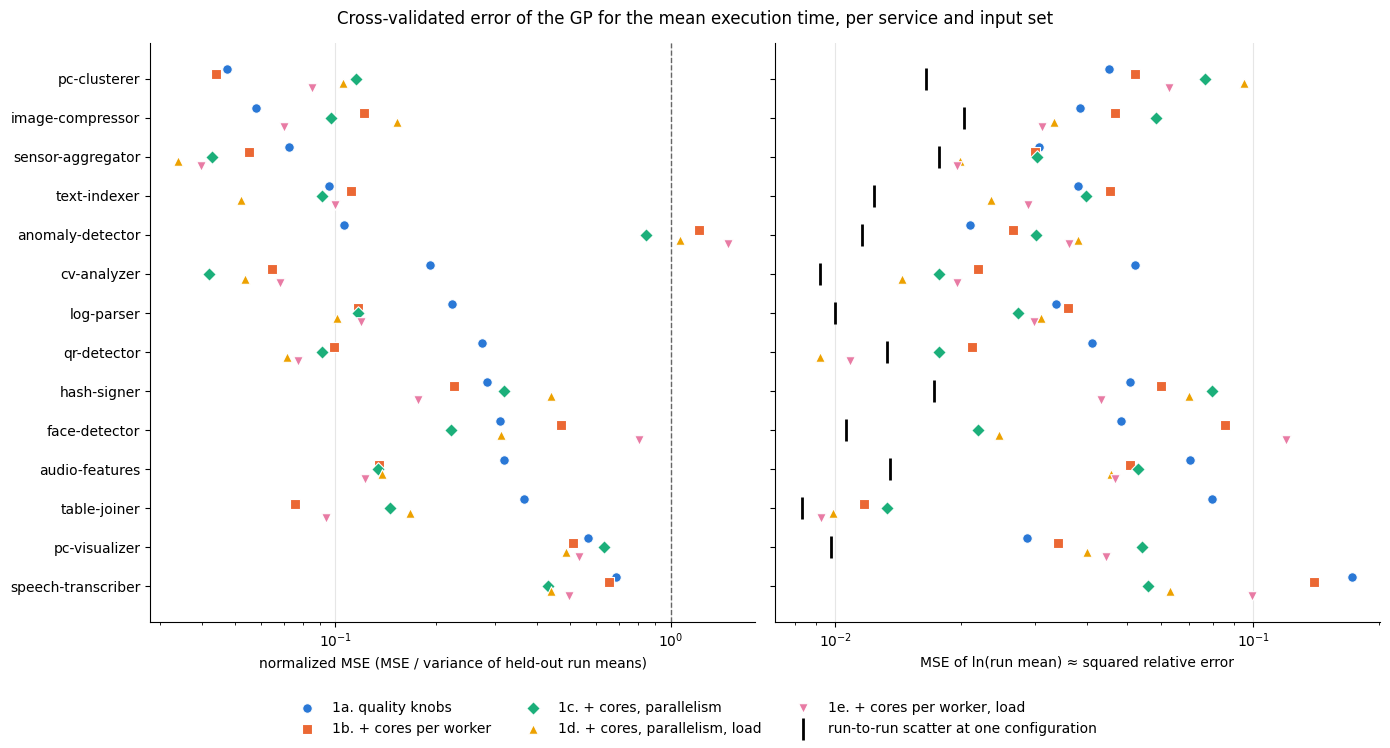

In [8]:
# Source: statics/results_milos (dataset.csv of every experiment), cross-validation of 1a-1e
styles = {"quality": ("1a. quality knobs", "#2a78d6", "o"),
          "cores_per_worker": ("1b. + cores per worker", "#eb6834", "s"),
          "cores_and_parallelism": ("1c. + cores, parallelism", "#1baf7a", "D"),
          "with_load": ("1d. + cores, parallelism, load", "#eda100", "^"),
          "cores_per_worker_with_load": ("1e. + cores per worker, load", "#e87ba4", "v")}
errors = mse_per_service(pd.concat(results.values(), ignore_index=True))
table = {metric: errors.pivot(index="service", columns="input_set", values=metric)[list(results)] for metric in ("nmse", "mse_log")}
order = table["nmse"]["quality"].sort_values().index
min_repeated = 5   # configurations with repeated runs that a service needs for its run-to-run scatter to be shown
scatter = pd.DataFrame([replicate_scatter(service) for service in order], index=order, columns=["variance", "configurations"])
scatter = scatter[scatter["configurations"] >= min_repeated]
labels = [service.split(":")[0] for service in order]

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
for ax, metric, xlabel in zip(axes, table, ["normalized MSE (MSE / variance of held-out run means)", "MSE of ln(run mean) ≈ squared relative error"]):
    for k, (name, (label, color, marker)) in enumerate(styles.items()):
        ax.scatter(table[metric].loc[order, name], np.arange(len(order)) + (k - 2) * 0.12, s=48, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=label, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axvline(1.0, color="0.4", linewidth=1, linestyle="--")
axes[1].scatter(scatter["variance"], [list(order).index(service) for service in scatter.index], marker="|", s=260, color="black",
                linewidth=2, label="run-to-run scatter at one configuration", zorder=2)
axes[0].set_yticks(np.arange(len(order)), labels)
axes[0].invert_yaxis()
handles = [handle for ax in axes for handle in ax.get_legend_handles_labels()[0]][:len(styles)] + axes[1].get_legend_handles_labels()[0][-1:]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Cross-validated error of the GP for the mean execution time, per service and input set")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Tests.** For each pair of input sets, the ratio of their MSEs is computed per service, and a Wilcoxon signed-rank
test asks whether the logarithms of these ratios are centered at 0 (no difference). Assumptions: the services are
independent of each other, and the log ratios are symmetric around their median; the folds and seeds of one service are
not independent, so they are pooled into one value per service before the test. With as few values as there are
services, the test can detect only a consistent difference.

In [9]:
pairs = [("cores_per_worker", "quality"), ("cores_and_parallelism", "quality"), ("cores_and_parallelism", "cores_per_worker"),
         ("with_load", "cores_and_parallelism"), ("cores_per_worker_with_load", "cores_per_worker"),
         ("cores_per_worker_with_load", "with_load")]

def comparison(metric: str, better: str, worse: str) -> str:
    ratio = table[metric][better] / table[metric][worse]
    return (f"{np.exp(np.log(ratio).median()):.2f}× in the median service, lower in {(ratio < 1).sum()} of {len(ratio)} services, "
            f"Wilcoxon p = {wilcoxon(np.log(ratio)).pvalue:.3f}")

short = {name: label.split(". ")[0] for name, (label, _, _) in styles.items()}
best = table["mse_log"].min(axis=1)   # MSE of the logarithm of the best input set of every service
display(Markdown("**What this shows** (MSE of input set A ÷ MSE of input set B; below 1: A is better).\n" + "\n".join(
    f"- **{short[a]} vs {short[b]}:** MSE {comparison('nmse', a, b)}; MSE of the logarithm {comparison('mse_log', a, b)}."
    for a, b in pairs)
    + f"\n- **Run-to-run scatter:** for the {len(scatter)} services with at least {min_repeated} repeated configurations, the best input set "
      f"of a service has an MSE of the logarithm of {np.median(best.loc[scatter.index] / scatter['variance']):.1f}× the scatter in the median service "
      f"(from {(best.loc[scatter.index] / scatter['variance']).min():.1f}× to {(best.loc[scatter.index] / scatter['variance']).max():.1f}×)."))

**What this shows** (MSE of input set A ÷ MSE of input set B; below 1: A is better).
- **1b vs 1a:** MSE 0.85× in the median service, lower in 10 of 14 services, Wilcoxon p = 0.268; MSE of the logarithm 1.11× in the median service, lower in 6 of 14 services, Wilcoxon p = 0.761.
- **1c vs 1a:** MSE 0.67× in the median service, lower in 9 of 14 services, Wilcoxon p = 0.296; MSE of the logarithm 0.90× in the median service, lower in 8 of 14 services, Wilcoxon p = 0.358.
- **1c vs 1b:** MSE 0.87× in the median service, lower in 9 of 14 services, Wilcoxon p = 0.463; MSE of the logarithm 1.03× in the median service, lower in 6 of 14 services, Wilcoxon p = 0.952.
- **1d vs 1c:** MSE 1.03× in the median service, lower in 6 of 14 services, Wilcoxon p = 0.761; MSE of the logarithm 0.84× in the median service, lower in 9 of 14 services, Wilcoxon p = 0.058.
- **1e vs 1b:** MSE 0.96× in the median service, lower in 7 of 14 services, Wilcoxon p = 0.670; MSE of the logarithm 0.81× in the median service, lower in 10 of 14 services, Wilcoxon p = 0.104.
- **1e vs 1d:** MSE 1.11× in the median service, lower in 5 of 14 services, Wilcoxon p = 0.670; MSE of the logarithm 1.01× in the median service, lower in 7 of 14 services, Wilcoxon p = 0.583.
- **Run-to-run scatter:** for the 13 services with at least 5 repeated configurations, the best input set of a service has an MSE of the logarithm of 1.9× the scatter in the median service (from 0.7× to 3.4×).

### 2. What Follows

- **Resources as inputs.** Giving the GP the resources (1b, 1c) lowers the MSE in ms² in most services, but not in
  all; the relative error (MSE of the logarithm) improves less consistently, and with the ratio $r / c$ alone it does
  not improve in the median service. The differences between the input sets are small compared with the differences
  between services, and none of the pairwise tests in 1f is significant at the 5% level. On this campaign, the data do not decide whether the resources
  should enter as the ratio $r / c$ or as $r$ and $c$.
- **Where the error comes from.** Even the best input set of a service stays above the run-to-run scatter for most
  services (black bars in 1f; the factor is printed below the tests). Only a part of the remaining error is therefore
  noise between runs; the rest is something that the model does not capture with these inputs. Two candidates, not tested here: the GP has one length scale for all
  inputs, so it cannot learn that one knob matters much more than another (a separate length scale per input would);
  and runs of the same configuration in different experiments (alone or in different pipelines) may differ for reasons
  that no knob describes.
- **The load.** Adding the load lowers the relative error (MSE of the logarithm) in most services, while the MSE in ms²
  does not change consistently. This is weak evidence that the execution times of the campaign depend on the load,
  which `explain_6` traces to CPU throttling and to warm-up after idle periods; it is what Assumption 3 of Pegasus
  excludes.

Limits:
- The MSE in ms² of a service is dominated by its runs with the longest execution times; e.g. a few runs of the anomaly
  detector take several times longer than all others and decide its MSE (its normalized MSE with resource inputs is close to
  or above 1, while its MSE of the logarithm is in the range of the other services). The MSE of the logarithm is the more robust of the two metrics.
- The tests have one value per service, and the services differ in their number of runs and configurations by more
  than an order of magnitude (setup cell); the speech transcriber has very few runs.
- The load $\lambda$ is measured in the run; a planner knows only the expected arrival rate, so 1d and 1e are an upper
  limit of what the load can contribute.